In [ ]:
import sys

print("Python version:", sys.version)
print("EconoCausal Week 1 started successfully!")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
EconoCausal Week 1 started successfully!


In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn dowhy econml -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 403.1/403.1 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.9/245.9 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 93.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 88.6 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv to Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20 (1).csv


In [ ]:
import pandas as pd
import numpy as np

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
file_name = "Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 64000
Columns: 12


In [ ]:
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [ ]:
print("Columns in dataset:")

for column in df.columns:
    print("-", column)

Columns in dataset:
- recency
- history_segment
- history
- mens
- womens
- zip_code
- newbie
- channel
- segment
- visit
- conversion
- spend


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


In [ ]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64


In [ ]:
print(df["segment"].value_counts())

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


In [ ]:
print(df["conversion"].value_counts())

conversion
0    63422
1      578
Name: count, dtype: int64


In [ ]:
conversion_rate = df["conversion"].mean() * 100

print(f"Overall conversion rate: {conversion_rate:.2f}%")

Overall conversion rate: 0.90%


In [ ]:
conversion_by_segment = (
    df.groupby("segment")["conversion"]
      .mean()
      .mul(100)
      .round(2)
)

print(conversion_by_segment)

segment
Mens E-Mail      1.25
No E-Mail        0.57
Womens E-Mail    0.88
Name: conversion, dtype: float64


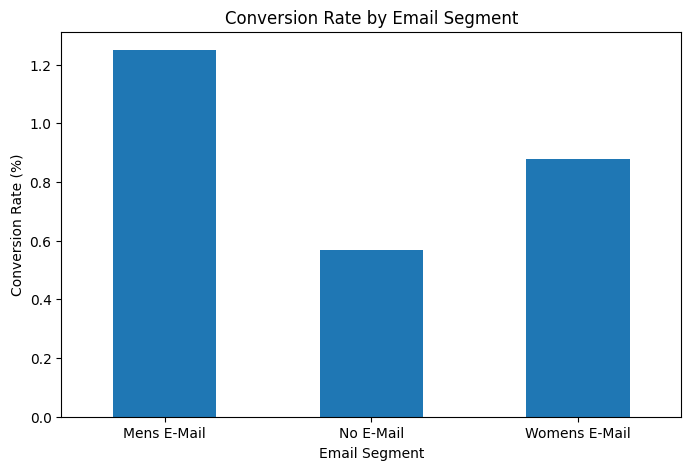

In [ ]:
import matplotlib.pyplot as plt

conversion_by_segment.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Conversion Rate by Email Segment")
plt.xlabel("Email Segment")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
treatment = "segment"
outcome = "conversion"

potential_confounders = [
    "recency",
    "history_segment",
    "history",
    "mens",
    "womens",
    "zip_code",
    "newbie",
    "channel"
]

print("Treatment:", treatment)
print("Outcome:", outcome)

print("\nPotential confounders:")
for variable in potential_confounders:
    print("-", variable)

Treatment: segment
Outcome: conversion

Potential confounders:
- recency
- history_segment
- history
- mens
- womens
- zip_code
- newbie
- channel


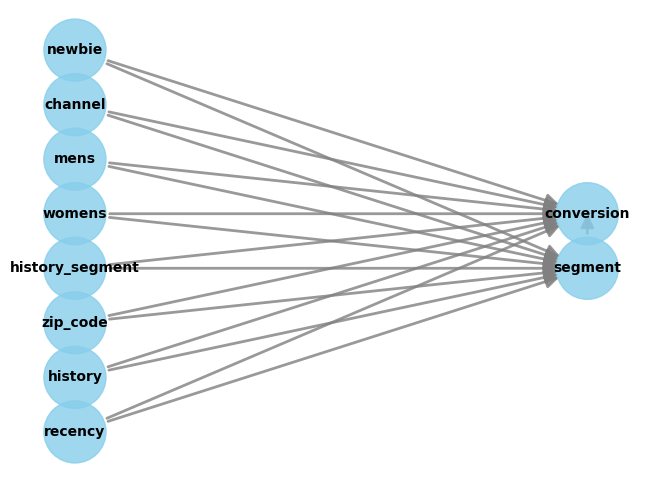

In [ ]:
from dowhy import CausalModel

model = CausalModel(
    data=df,
    treatment="segment",
    outcome="conversion",
    common_causes=potential_confounders
)

model.view_model()

In [ ]:
df["email_treatment"] = (df["segment"] != "No E-Mail").astype(int)

print(df[["segment", "email_treatment"]].head(10))

         segment  email_treatment
0  Womens E-Mail                1
1      No E-Mail                0
2  Womens E-Mail                1
3    Mens E-Mail                1
4  Womens E-Mail                1
5  Womens E-Mail                1
6  Womens E-Mail                1
7  Womens E-Mail                1
8    Mens E-Mail                1
9  Womens E-Mail                1


In [ ]:
print(df["email_treatment"].value_counts())

email_treatment
1    42694
0    21306
Name: count, dtype: int64


In [ ]:
conversion_by_treatment = df.groupby("email_treatment")["conversion"].mean()

print(conversion_by_treatment)

email_treatment
0    0.005726
1    0.010681
Name: conversion, dtype: float64


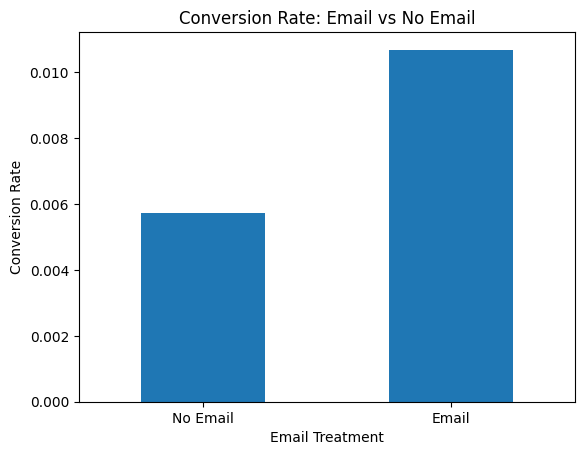

In [ ]:
import matplotlib.pyplot as plt

conversion_by_treatment.plot(kind="bar")

plt.title("Conversion Rate: Email vs No Email")
plt.xlabel("Email Treatment")
plt.ylabel("Conversion Rate")
plt.xticks([0, 1], ["No Email", "Email"], rotation=0)
plt.show()